## Градиентный спуск на NumPy

Рассмотрим функцию $f(\mathbf{x})$, $x \sim (2)$ на отрезке [0, 10]:

$$f(\mathbf{x}) = \sin(x_1)\cos(x_2) + \sin(0.5x_1)\cos(0.5 x_2)$$

1. Реализуйте функцию в векторизованном виде, т.е. для матрицы $\mathbf{X} \sim (n, 2)$ она должна возвращать вектор $f(\mathbf{X}) \sim (n)$, где $[f(\mathbf{X})]_i = f(\mathbf{X}_i)$
2. Реализуйте функцию `grad(X)`, которая будет вычислять градиент функции $f(\mathbf{X})$
3. Напишите процедуру градиентного спуска и визуализируйте траектории процесса оптимизации из нескольких различных начальных точек (используйте то, что ваша функция векторизована!)
4. Когда мы перейдём к обучению нейронных сетей, направление наискорейшего спуска для функции ошибки может быть очень шумным, и для ускорения сходимости существует несколько техник для выбора лучшего направления спуска. Одна из самых популярных и простых — добавление инерции (momentum):
    $$
    \begin{align*}
    \mathbf{g}_0 &= 0 \\
    \mathbf{g}_t &= - \eta \nabla f(\mathbf{x}_{t-1}) + \lambda \mathbf{g}_{t-1} \\
    \mathbf{x}_{t} &= \mathbf{x}_{t-1} + \mathbf{g}_t
    \end{align*}
    $$
    Сделайте градиентный спуск с инерцией и визуализируйте норму градиентов, она должна сходиться к нулю по мере приближения к стационарным точкам.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

#1
def f(X):
  x1 = X[:, 0]
  x2 = X[:, 1]

  res = np.sin(x1)*np.cos(x2) + np.sin(0.5*x1)*np.cos(0.5*x2)

  return res

#2
def grad(X):
  x1 = X[:, 0]
  x2 = X[:, 1]

  df_dx1 = np.cos(x1)*np.cos(x2) + 0.5*np.cos(0.5*x1)*np.cos(0.5*x2)
  df_dx2 = np.sin(x1)*(-np.sin(x2)) + 0.5*np.sin(0.5*x1)*(-np.sin(0.5*x2))

  return np.column_stack([df_dx1, df_dx2])

#3
def grad_desc(start_points, learning_rate):
  trajs = []
  for x0 in start_points:
      x = x0.copy()
      traj = [x.copy()]
      for _ in range(1000):
          g = grad(x.reshape(1, -1))[0]
          x = x - learning_rate*g
          traj.append(x.copy())
      trajs.append(np.array(traj))
  return trajs

#4
def grad_desc_momentum(start_points, learning_rate, lambd):
  trajs = []
  grad_norms = []
  for x0 in start_points:
      x = x0.copy()
      traj = [x.copy()]
      g_prev = np.zeros_like(x)
      norms = []

      for _ in range(1000):
          g = grad(x.reshape(1, -1))[0]
          g_new = -learning_rate*g + lambd*g_prev
          x = x + g_new
          norms.append(np.linalg.norm(g))
          traj.append(x.copy())
          g_prev = g_new

      trajs.append(np.array(traj))
      grad_norms.append(norms)

  return trajs, grad_norms

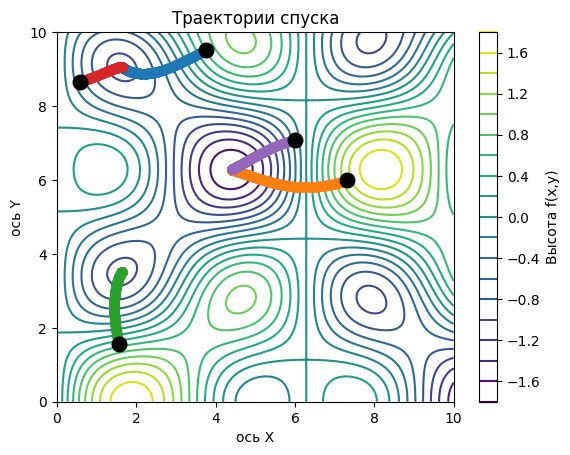

In [5]:
np.random.seed(42)
starts = np.random.uniform(0, 10, size=(5, 2))
trajs = grad_desc(starts, 0.01)

x1 = np.linspace(0, 10, 200)
x2 = np.linspace(0, 10, 200)
X1, X2 = np.meshgrid(x1, x2)
f_values = f(np.column_stack([X1.ravel(), X2.ravel()])).reshape(X1.shape)

contour = plt.contour(X1, X2, f_values, levels=20, cmap='viridis')
plt.colorbar(contour, label='Высота f(x,y)')

plt.title("Траектории спуска")
plt.xlabel("ось X")
plt.ylabel("ось Y")
for t in trajs:
    plt.plot(t[:, 0], t[:, 1], 'o-')
    plt.plot(t[0, 0], t[0, 1], 'o', color='black', markersize=10,
             markeredgecolor='black', markeredgewidth=1.5)

plt.show()

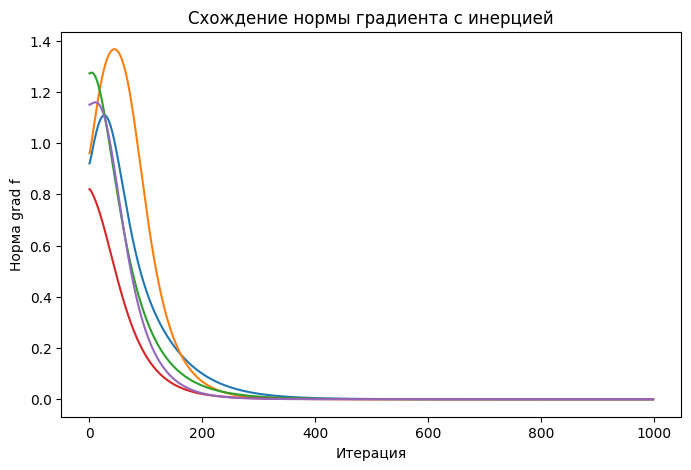

In [6]:
np.random.seed(42)
starts = np.random.uniform(0, 10, size=(5, 2))
trajs, grad_norms = grad_desc_momentum(starts, 0.01, 0.5)

plt.figure(figsize=(8, 5))
for norms in grad_norms:
  plt.plot(norms)

#plt.yscale("log")
plt.title("Схождение нормы градиента с инерцией")
plt.xlabel("Итерация")
plt.ylabel("Норма grad f")
plt.show()